# Visión por Computador - Práctica 2 - Deep Learning en Computer Vision

#### 15 puntos   |   Fecha de entrega: 7 de Diciembre, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2526.ugr.es/

### Estudiante: Jose María Martín Martín

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.






### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2526.ugr.es/mod/folder/view.php?id=95307):
-  Introducción a Python: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/2.%20Introducción%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf (y Notebook asociado: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Algunas%20ideas%20sobre%20cómo%20elaborar%20un%20informe%20académico-científico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2526.ugr.es/pluginfile.php/243164/mod_folder/content/0/Ejemplo_Otsu.ipynb

# <font color='blue'>**Ejercicio  3: Transfer Learning y fine-tuning con ResNet34 en el SPR X-Ray Age Prediction Challenge (4 points)**
<font color='blue'>En este ejercicio trabajaremos con el _SPR X-Ray Age Prediction Challenge_ de Kaggle (https://www.kaggle.com/competitions/spr-x-ray-age/data). Este dataset consta de $10 702$ radiografías de tórax, y el objetivo es predecir la edad de la persona a partir de la imagen de la radiografía. En esta ocasión, se emplearán $6 702$ imágenes para entrenamiento y $4 000$ para test. Las edades oscilan entre los 18 y los 89 años. Para facilitar el trabajo al alumnado se proporciona una versión procesada de los datos (con resolución $224\times224$, en lugar de $1024\times1024$, y empleando solo ejemplos para los cuales se tiene salida deseada (dado que, al tratarse de una challenge de kaggle, el conjunto de test está disponible pero sin etiquetar)). Estos datos se pueden acceder desde: https://drive.google.com/drive/folders/1hCWfTLs1w0h5kObl6NEIhEtH5VDmmCnj?usp=sharing (se debe emplear una cuenta de la UGR para acceder a dicha URL, y la información allí contenida (directorio `spr-x-ray-age`) se debe incluir en la carpeta `Colab Notebooks`).

<font color='blue'>Se debe emplear un $20\%$ de los datos de entrenamiento para validación, y el rendimiento debe ser evaluado, como mínimo, por medio de $MSE$, $MAE$ y $R^2$ _(coefficient of determination) score_. Se deben justificar las decisiones tomadas, como la elección de la función de pérdida. Del mismo modo, es necesario hacer un `summary()` de las arquitecturas empleadas en cada apartado, indicando qué parámetros/capas/bloques son entrenables y cuáles no lo son (es decir, en cada apartado es imprescindible destacar claramente qué arquitectura exacta se está utilizando, así como qué pesos se están entrenando y cuáles se están congelando).

<font color='blue'>Usaremos un modelo ResNet34 pre-entrenado en ImageNet, y tendremos que realizar los experimentos, y responder las preguntas, que se muestran a continuación:

  <font color='blue'>
  
  1. (0.75 puntos) Partimos de ResNet34, adaptamos la cabecera (sustituyendo la cabecera anterior por *una única fully-connected* con el número de neuronas de salida adecuado), y reentrenamos (_from scratch_) la red entera para este nuevo problema durante $15$ épocas. Es decir, partimos de pesos aleatorios para resolver este problema de regresión.

  <font color='blue'>

  2. <font color='blue'> (1.25 puntos) Partimos de ResNet34, adaptamos la cabecera (empleando la misma del apartado anterior), y entrenamos solo la cabecera incorporada. Es decir, ResNet34 se usa como un mero extractor de características (preentrenado en ImageNet), y los pesos que se entrenan  durante $15$ épocas son los de la nueva capa incorporada (manteniendo fijos/congelados todos los demás). Como parte de este apartado se deben responder las dos siguientes preguntas:
  
      - <font color='blue'> (0.25 puntos) Si no se especifica ninguna `custom_head`, ¿qué incorpora fastai por defecto?
      - <font color='blue'> (0.25 puntos) Estamos intentando resolver un problema de regresión por medio de la reutilización de un modelo pre-entrenado en un problema de clasificación (ImageNet). ¿Tiene sentido hacerlo? ¿Por qué nos sirven pesos entrenados en clasificación para un problema de regresión? ¿No son, acaso, problemáticas muy diferentes?

  <font color='blue'>

  3. <font color='blue'>(1 punto) Partimos de ResNet34, empleamos la cabecera del apartado anterior, y hacemos un ajuste fino de toda la red partiendo de los pesos de ResNet34 (preentrenada en ImageNet) durante $15$ épocas: $5$ para la cabecera y $10$ para toda la red. En base a toda la experimentación realizada hasta ahora en los tres apartados:

      - <font color='blue'> (0.25 puntos) ¿Qué conclusiones se pueden extraer? En caso de que nos enfrentemos a un nuevo problema, ¿qué opción, u opciones, de entre las anteriores, parece a priori la más razonable? ¿Por qué?

4. <font color='blue'>(1 punto) Partimos de ResNet34, empleamos la cabecera del apartado anterior, y hacemos un ajuste fino de toda la red partiendo de los pesos de ResNet34 (preentrenada en ImageNet) durante $15$ épocas: $5$ para la cabecera y $10$ para toda la red. Pero, en este caso, enfocamos el problema como uno de clasificación con tantas clases como años contiene nuestro dataset ($[18, 89]$). El alumnado debe emplear, al menos, dos métricas de clasificación para evaluar el rendimiento. ¿Qué conclusiones extrae de este experimento? ¿Qué aproximación, a priori, parece más adecuada: regresión o clasificación?

<font color='blue'>Nota: en todo el enunciado de este ejercicio, cuando se habla de sustituir la cabecera "por una única fully-connected con el número de neuronas de salida adecuado", se trata de hacer eso literalmente (como máximo se puede añadir una capa de flattening, pero no se pueden usar capas de pooling).

In [ ]:
!pip install -U "fastai==2.7.15" "fastcore==1.5.29" "fastprogress==1.0.3" "fastdownload==0.0.7"
from fastai.vision.all import *

In [ ]:
import pandas as pd
import os

In [ ]:
# # We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Function to display evaluation metrics
# Developed by Ignacio Oguiza: https://forums.fast.ai/t/plotting-metrics-after-learning/69937

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.stack(self.values)
    names = self.metric_names[1:-1]
    n = len(names) - 1
    if nrows is None and ncols is None:
        nrows = int(math.sqrt(n))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None: nrows = int(np.ceil(n / ncols))
    elif ncols is None: ncols = int(np.ceil(n / nrows))
    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = [ax if i < n else ax.set_axis_off() for i, ax in enumerate(axs.flatten())][:n]
    for i, (name, ax) in enumerate(zip(names, [axs[0]] + axs)):
        ax.plot(metrics[:, i], color='#1f77b4' if i == 0 else '#ff7f0e', label='valid' if i > 0 else 'train')
        ax.set_title(name if i > 1 else 'losses')
        ax.legend(loc='best')
    plt.show()

In [ ]:
!ls drive/MyDrive/Colab\ Notebooks/spr-x-ray-age/
# !ls gdrive/MyDrive/Colab\ Notebooks/spr-x-ray-age/

All_labels.csv	test  train


In [ ]:
train_folder = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/train'
test_folder = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/test'
csv_path = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/All_labels.csv'

In [ ]:
if os.path.exists(csv_path):
    print("CSV File exists!")
    # reading the labels dataframe
    df = pd.read_csv(csv_path, dtype=float, index_col=0)
    print(f'Dataframe shape: {df.shape}')
else:
    print("File does not exist.")

CSV File exists!
Dataframe shape: (10702, 1)


In [ ]:
# defining the dataset paths
train_path = Path(train_folder)
test_path = Path(test_folder)

# reading the folders looking for images
train_files = get_image_files(train_path)
test_files = sorted(get_image_files(test_path))

print(f'{len(train_files)} files were found for training and {len(test_files)} files were found for test')

6702 files were found for training and 4000 files were found for test


Age varies from 18.0 to 89.0



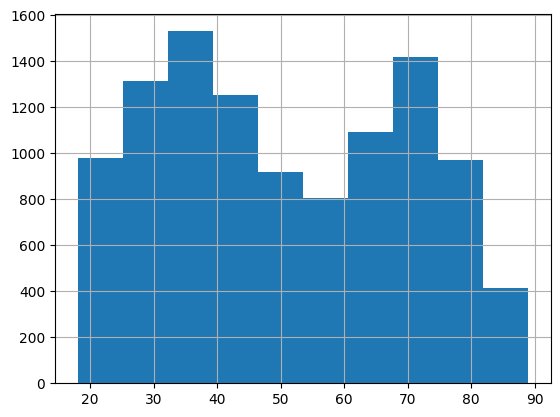

In [ ]:
print(f'Age varies from {df.age.min()} to {df.age.max()}\n')
_=df.age.hist()

In [ ]:
# function used to retun the label from an image
def label_func(file):
    # takes the file's base name w/o the extension
    basename = int(os.path.basename(str(file)).split('.')[0])

    # searches for the label
    label = int(df.age[basename])

    return label

Para la construcción del Datablock se tienen las siguientes cosas en cuenta:


*   Es un problema de regresión, por tanto debemos cambiar **CategoryBlock** a **RegressionBlock**.
*   El porcentaje de conjunto de validación cambia ahora al 20%.
*   Para el tamaño del batch, vamos a tomar 128 porque es un tamaño razonable y por uso en anteriores ejercicios.
*   En cuanto a tamaño, seleccionamos 224, que es el de las imágenes de nuestro dataset.
*   Además, utilizamos la función **label_func** para extraer las etiquetas dada la imagen.
*   Se va a normalizar los datos aplicando Normalize().



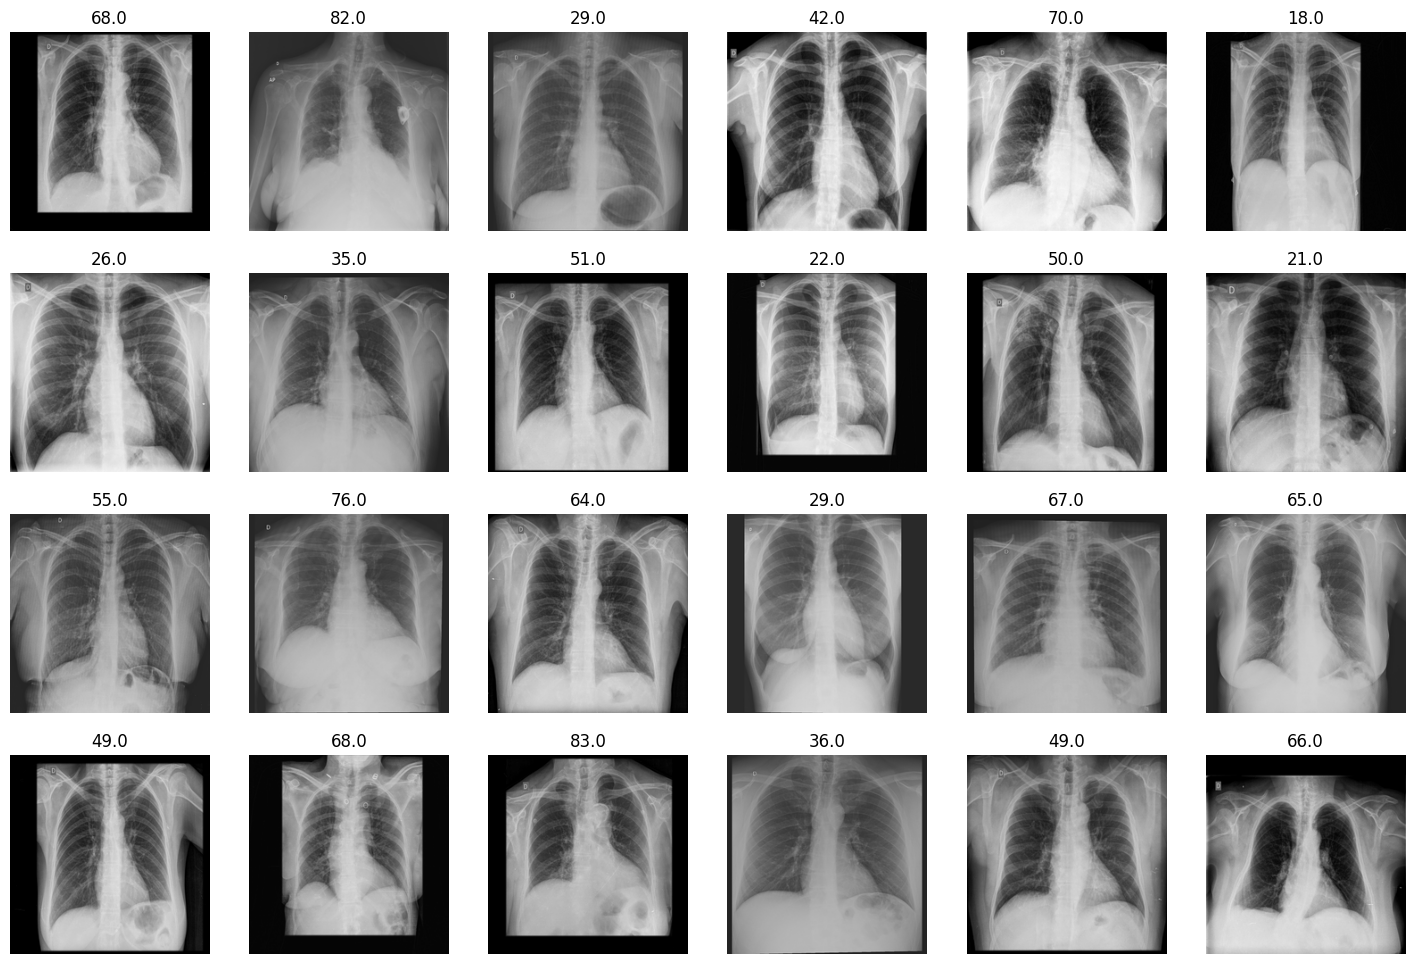

In [ ]:

dtblk = DataBlock(
    blocks=(ImageBlock, RegressionBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=label_func,
    item_tfms=[Resize(224)],
    batch_tfms= Normalize()
    )
dls = dtblk.dataloaders(train_path, bs=128)

dls.show_batch(max_n=24)

In [ ]:
print('Numero de ejemplos de entrenamiento (una vez descartados los de validacion):', len(dls.train_ds))
print('Numero de ejemplos de validacion:', len(dls.valid_ds))

Numero de ejemplos de entrenamiento (una vez descartados los de validacion): 5362
Numero de ejemplos de validacion: 1340


## <font color='blue'>3.1 Entrenamos todo ResNet34 _from scratch_, ajustando la cabecera para este problema. (0.75 puntos)

Antes que nada, queremos visualizar el modelo original. Esto lo hacemos para poder visualizar el número de características que van a entrar a nuestra **custom_head**. Normalmente  se suele aplicar una capa de pooling global ( como en el ejercicio 4 ) que reduce la salida del body del modelo a dimensión (bs,n_features,1,1) pero en este caso se nos prohíbe hacerlo. De la forma anterior, podemos acceder al número de características del modelo mediante **num_features = num_features_model(body)** y pasarle ese número a la capa FC pero en nuestro caso tenemos que ver el tamaño de los datos.

In [ ]:
learn = vision_learner(dls, resnet34, pretrained=False)
learn.summary()

Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       True      
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                     

Como podemos observar, antes de las dos capas de adaptative pooling que dan lugar al head del modelo, el bloque proporciona una salida de dimensión (bs, 512, 7, 7). Entonces la capa FC de nuestro head deberá recibir **512x7x7** features.

Para crear el nuevo modelo necesitamos definir una cabecera. Esta estará formada por una capa de **Flatten** seguida de la capa FC que se nos pide.
Para construir el modelo a partir de **resnet34**, utilizamos **vision_learner** que nos permite crear un learn a partir de un modelo predefinido. En nuestro caso asignamos un **custom_head** para sustituir la cabecera de resnet por la nuestra. Además, seleccionamos los pesos no preentrenados. También se han de definir las métricas y la función de pérdida. En nuestro caso vamos a seleccionar las siguientes.

**<h1>Función de pérdida</h1>**

La función de pérdida tiene que ser algo que compare la predicción del valor que devuelve el modelo con el valor real. En este contexto lo más común es usar el **MSE** que a diferencia con el **MAE** ( detallado más adelante ), penaliza errores más grandes.

$$
\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

**<h1>Métricas</h1>**

$$
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}\lvert y_i - \hat{y}_i \rvert
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

$$
\bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i
$$

En este caso, el R2 explica que parte de la variabilidad de los datos queda explicada por el modelo. Tanto el MAE como el MSE sirven para ver más o menos cuánto nos hemos equivocado con la predicción. No representan lo mismo y el MSE penaliza más las predicciones más alejadas del valor real. Si tomamos su raíz cuadrada ( RMSE ) podemos ver esta diferencia con el MAE.

In [ ]:
# A CUBRIR POR EL ALUMNADO
# Extraemos el cuerpo del modelo para tener el número de
# características de salida de la última capa del cuerpo.
modelo = models.resnet34(pretrained=False)
body = create_body(modelo)
num_features = num_features_model(body)

# Creamos la cabecera con el numero de caracteristicas
# y de salida 1 ( regresion )
custom_head = nn.Sequential(
                            nn.Flatten(),
                            nn.Linear(num_features * 7 * 7, 1))

# Creamos finalmente el modelo con el conjunto de datos,
# nuestra cabecera personalizada, las métricas MSE, MAE
# y R2 y sin entrenar.
learn1 = vision_learner(dls,
                          resnet34,
                          loss_func=MSELossFlat(),
                          metrics=[mse,mae , R2Score()],
                          custom_head = custom_head,
                          pretrained=False)
learn1.summary()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       True      
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
Conv2d                                    36864      True      
BatchNorm2d                               128        True      
ReLU                     

En cuánto a parámetros entrenables tenemos **21,309,761 parámetros** y no entrenables 0. Esto es porque hemos seleccionado que no queremos pesos preentrenados y por tanto vamos a entrenar toda la red desde 0.
Una vez construído el modelo, procedemos al entrenamiento from scratch con 15 épocas, seleccionando una lr de 0.01 por ser un valor razonable y por su uso en el ejercicio anterior.

epoch,train_loss,valid_loss,mse,mae,r2_score,time
0,2711.899414,6608.475586,6608.475586,33.640892,-18.681608,00:29
1,1067.039307,321.334808,321.334808,15.223989,0.042989,00:28
2,606.400757,305.483734,305.483734,14.766952,0.090197,00:28
3,414.390686,346.635864,346.635864,15.740112,-0.032364,00:29
4,325.842529,318.254852,318.254852,14.418199,0.052162,00:28
5,272.866364,250.273117,250.273117,12.750497,0.254627,00:28
6,227.476379,562.365417,562.365417,19.878803,-0.674857,00:29
7,203.880035,628.805176,628.805176,21.003378,-0.872731,00:28
8,175.331085,230.583786,230.583786,12.118204,0.313267,00:28
9,166.323990,183.123856,183.123856,10.623698,0.454614,00:29


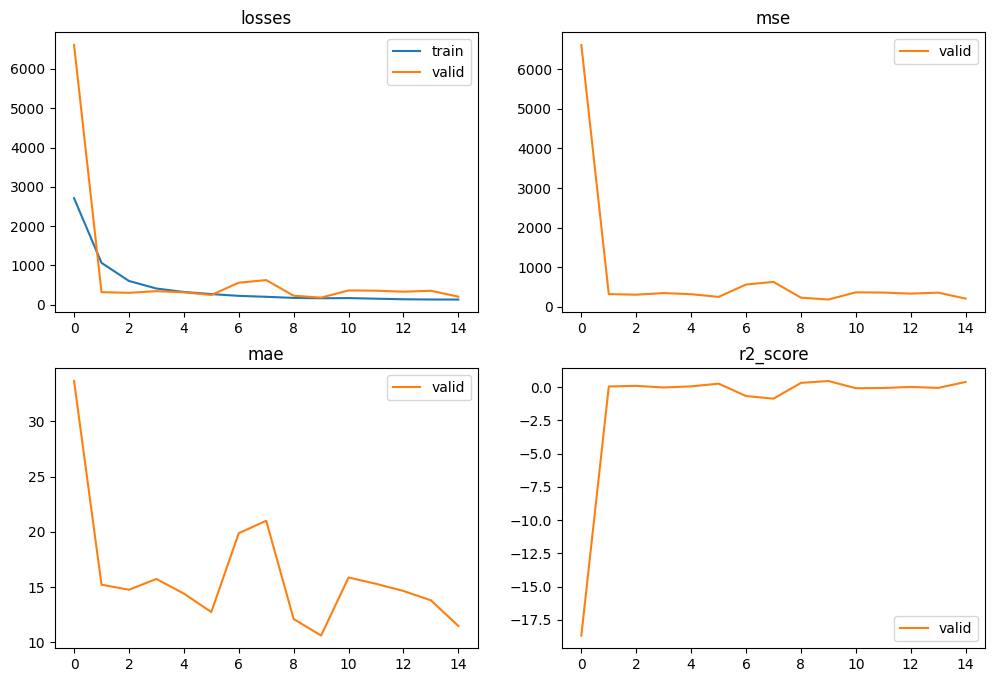

In [ ]:
# A CUBRIR POR EL ALUMNADO
n_epochs = 15
learn1.fit(n_epochs, lr=0.01)
learn1.recorder.plot_metrics()

Observaciones:


*   Los resultados de las métricas son en general bastante pobres.
*   Si nos fijamos en el **MSE** tenemos que obtenemos un valor entorno a 207. Esto nos dice que de media la predicción de la edad fallamos entorno a 14 años por arriba o por abajo lo cual es bastante bajo.
*   En cuanto al MAE, vemos algo parecido al comentario que hemos hecho con el RMSE ( que es la raíz del MSE, de donde hemos sacado la predicción errónea de entorno a 14 años ). En este caso tenemos un error de unos 11 años, lo cuál es también muy pobre. ¿ Por qué entonces el RMSE y el MAE no coinciden ? Pues porque como el MSE al principio calcula un error al cuadrado, se penaliza más las predicciones más alejadas de la edad real.
* Por último el coeficiente de determinación da un valor de entorno al **0.38**. Esta métrica explica que proporción de la variabilidad de la variable es explicada por el modelo, por lo que un 38% es bastante malo.
*   En cuanto a potencial sobreajuste, no podemos ver un sobreajuste grande y claro en la comparativa de funciones de pérdida.



## <font color='blue'>3.2. ResNet34 se usa como extractor de características: Entrenamos solo la cabecera incorporada. (1.25 puntos)



Vamos ahora a entrenar el mismo modelo pero con los pesos preentrenados del cuerpo de **resnet34**. Para ello rescatamos la cabecera calculada en el ejercicio anterior y el número de características. Además, se usan las mismas métricas y función de pérdida que en el ejercicio anterior ( previamente explicadas ).

In [ ]:
# A CUBRIR POR EL ALUMNADO

# misma cabecera que en el ejercicio anterior
custom_head = nn.Sequential(
                            nn.Flatten(),
                            nn.Linear(num_features * 7 * 7, 1))

# En este caso tomamos los pesos preentrenados
learn2 = vision_learner(dls,
                          resnet34,
                          loss_func=MSELossFlat(),
                          metrics=[mse,mae , R2Score()],
                          custom_head = custom_head,
                          pretrained=True)
learn2.summary()

Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                     

En cuánto a qué parámetros son entrenables y cuáles no, en este caso tenemos que de los **21,309,761**, solo **42,113** son entrenables. Aparentemente solo deberíamos tener los **25,089** de la capa FC. Los otros si nos fijamos en el summary, todas las capas de **Batch Normalization** tienen True en la 3era columna. Esto es porque estas capas afectan a la escala de nuestros datos y por tanto por defecto se deben entrenar y no se congelan. En cada capa de este tipo tenemos 2 parámetros por número de canales.

Por último, realizamos el fine tuning que se nos dice, donde entrenamos la cabecera por 15 épocas y usamos el cuerpo de resnet como un mero extractor de características.

In [ ]:
learn2.fine_tune(epochs=0, freeze_epochs=15)


epoch,train_loss,valid_loss,mse,mae,r2_score,time
0,816.640259,567.717834,567.717834,19.613390,-0.690798,00:22
1,518.139771,325.534332,325.534332,14.929014,0.030482,00:22
2,365.089294,226.974762,226.974762,12.474656,0.324015,00:22
3,270.439758,174.842743,174.842743,10.618140,0.479277,00:23
4,206.708832,142.846893,142.846893,9.494903,0.574568,00:22
5,163.191574,123.888466,123.888466,8.806312,0.631031,00:23
6,136.708282,136.208908,136.208908,9.181713,0.594338,00:22
7,115.669640,107.683830,107.683830,8.166319,0.679292,00:23
8,98.824059,114.269310,114.269310,8.370193,0.659679,00:22
9,98.551094,211.119217,211.119217,12.055217,0.371237,00:22


En este caso no tenemos las gráficas ya que al entrenar todas las capas por 0 épocas, no se guardan métricas ( ni siquiera las de entrenar solo la cabecera ). Aún así, se pueden sacar conclusiones. Observaciones:
*   Los resultados son malos pero algo mejores que en el ejercicio anterior.
*   Los valores del **MSE** y **MAE** sugieren un error de unos 8-11 años.
*   El coeficiente de determinación es de un **0.65**.
*   Tampoco se aprecia sobreajuste, ya que la pérdida en validación pese a que tenga repuntes, la tendencia por lo general parece baja, lo que sugiere que faltan épocas de entrenamiento para ver en que punto ( si es que llega ) se estabiliza.

### <font color='blue'>Si no se especifica ninguna `custom_head`, ¿qué incorpora fastai por defecto?

Para responder a esta pregunta, vamos a construir el modelo sin custom_head y ver su arquitectura.

In [ ]:
learn_no_head = vision_learner(dls,
                          resnet34,
                          loss_func=MSELossFlat(),
                          metrics=[mse,mae , R2Score()],
                          pretrained=True)
learn_no_head.summary()

Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                     

Si nos fijamos en el último bloque de capas convolucionales de nuestro modelo en el ejercicio anterior, tenemos la siguiente arquitectura:


     
                     128 x 512 x 7 x 7   

**Capa**            **Parámetros**   
Conv2d                                    1179648    True      
BatchNorm2d                               1024       True      
ReLU                                                           
Conv2d                                    2359296    True      
BatchNorm2d                               1024       True      
Conv2d                                    131072     True      
BatchNorm2d                               1024       True      
Conv2d                                    2359296    True      
BatchNorm2d                               1024       True      
ReLU                                                           
Conv2d                                    2359296    True      
BatchNorm2d                               1024       True      
Conv2d                                    2359296    True      
BatchNorm2d                               1024       True      
ReLU                                                           
Conv2d                                    2359296    True      
BatchNorm2d                               1024       True      
____________________________________________________________________________

A este bloque le sigue nuestra cabecera personalizada, formada por flatten más la capa FC.

En cambio, en este caso vemos como tras el último bloque, hay dos capas de **adaptive pooling**, una de ellas empleando la media y la otra el máximo.

____________________________________________________________________________
                     128 x 512 x 1 x 1   
AdaptiveAvgPool2d                                              
AdaptiveMaxPool2d  

A esto le sigue:
____________________________________________________________________________
                     128 x 1024          
Flatten                                                        
BatchNorm1d                               2048       True      
Dropout                                                        
____________________________________________________________________________
                     128 x 512           
Linear                                    524288     True      
ReLU                                                           
BatchNorm1d                               1024       True      
Dropout                                                        
____________________________________________________________________________
                     128 x 1             
Linear                                    512        True      
____________________________________________________________________________


Donde como vemos se aplica **batch_normalization** y **dropout** tanto después de Flatten como de la primera capa FC ( que tiene una función de activación Relu ) y por último tiene una capa FC de salida que proporciona un valor para la regresión.

### <font color='blue'> Estamos intentando resolver un problema de regresión por medio de la reutilización de un modelo pre-entrenado en un problema de clasificación (ImageNet). ¿Tiene sentido hacerlo? ¿Por qué nos sirven pesos entrenados en clasificación para un problema de regresión? ¿No son, acaso, problemáticas muy diferentes?

Esta pregunta tiene todo el sentido plantearla. Pese a que pueda parecer que no es el mismo tipo de problemática, no tenemos que pensar en los pesos del cuerpo del modelo ( ya que lo que modificamos es la cabecera ) como predictores de clases sino como extractores de características. Es por esto que pesos entrenados para un problema de clasificación nos sirve para uno de regresión porque de lo que se encargan estas capas convolucionales es de extraer características lo cuál es común a ambas problemáticas. Para usar un modelo preentrenado para regresión, basta con definir una cabecera ( con las capas FC y otras capas que sean convenientes ) y terminar con una capa que tenga como output un único valor, que es el valor a predecir. Además de esto, es necesario definir las métricas y función de pérdida relativas a regresión.

## <font color='blue'>3.3. Hacemos un ajuste fino (fine-tuning) de toda la red partiendo de los pesos de ImageNet. (1 punto)

Vamos a proceder a entrenar el mismo modelo que en el apartado anterior pero modificando el número de épocas de entrenamiento de la red entera. Además, se usan las mismas métricas y función de pérdida que en el ejercicio anterior ( previamente explicadas ).

In [ ]:
# A CUBRIR POR EL ALUMNADO
custom_head = nn.Sequential(
                            nn.Flatten(),
                            nn.Linear(num_features * 7 * 7, 1))
learn3 = vision_learner(dls,
                          resnet34,
                          loss_func=MSELossFlat(),
                          metrics=[mse,mae , R2Score()],
                          custom_head = custom_head,
                          pretrained=True)
learn3.summary()


Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                     

Igual que en el ejercicio anterior, en cuánto a qué parámetros son entrenables y cuáles no, en este caso tenemos que de los **21,309,761**, solo **42,113** son entrenables. Aparentemente solo deberíamos tener los **25,089** de la capa FC. Los otros si nos fijamos en el summary, todas las capas de **Batch Normalization** tienen True en la 3era columna. Esto es porque estas capas afectan a la escala de nuestros datos y por tanto por defecto se deben entrenar. En cada capa de este tipo tenemos 2 parámetros por número de canales.

Finalmente, hacemos el fine tuning entrenando la cabecera por 5 épocas y después la red entera durante 10 épocas.

epoch,train_loss,valid_loss,mse,mae,r2_score,time
0,882.136353,692.619446,692.619446,21.520781,-1.062785,00:22
1,489.524292,228.478363,228.478363,12.302836,0.319537,00:22
2,298.666077,153.290634,153.290634,9.822461,0.543464,00:22
3,201.219940,124.864014,124.864014,8.788663,0.628125,00:22
4,152.005295,105.122017,105.122017,8.031003,0.686922,00:22


epoch,train_loss,valid_loss,mse,mae,r2_score,time
0,80.894943,87.590408,87.590408,7.332158,0.739135,00:29
1,56.831127,84.219971,84.219971,7.222393,0.749173,00:29
2,40.948376,78.891747,78.891747,6.975897,0.765042,00:29
3,36.185284,91.705788,91.705788,7.598074,0.726878,00:29
4,29.094103,64.271370,64.271370,6.300309,0.808585,00:29
5,22.878992,62.774574,62.774574,6.205008,0.813042,00:29
6,13.548022,61.236855,61.236855,6.136111,0.817622,00:29
7,8.974160,61.173508,61.173508,6.130174,0.817811,00:29
8,6.006303,60.978249,60.978249,6.109055,0.818392,00:29
9,4.371020,60.864716,60.864716,6.126802,0.818730,00:29


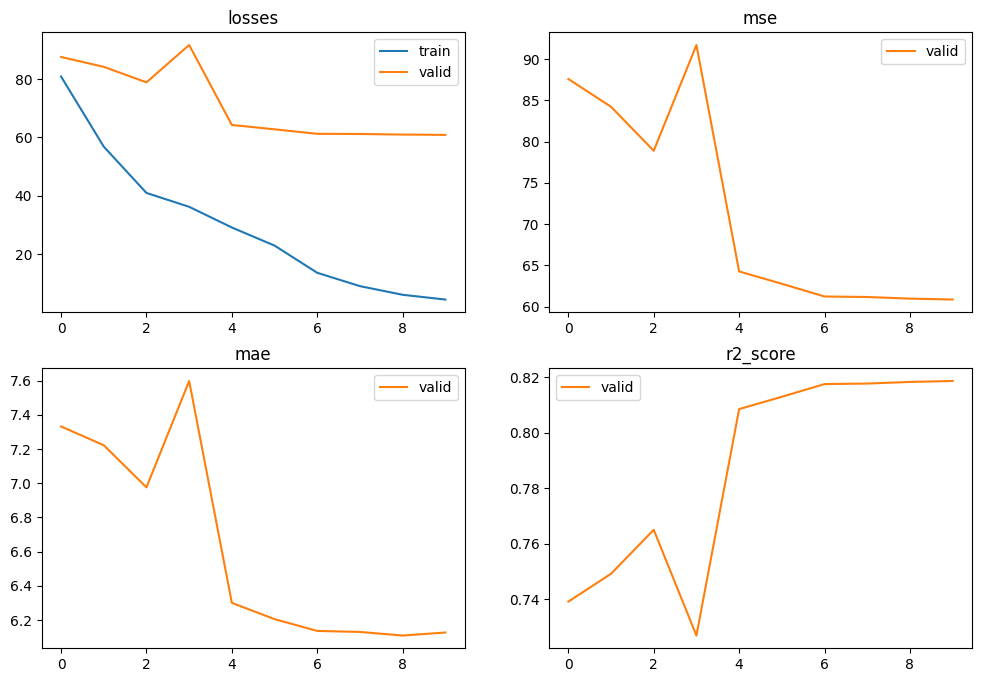

In [ ]:
learn3.fine_tune(epochs=10, freeze_epochs=5)
learn3.recorder.plot_metrics()

Observaciones:
*   Volvemos a tener un entrenamiento malo pero bastante mejor que en los casos anteriores.
*   Tenemos un **MSE** de 60 y un **MAE** de 6, que nos indican más o menos que el error cometido medio es de 6 a 8 años.
*   El coeficiente de determinación presenta un valor del **0.8**, que empieza a ser un valor medianamente aceptable.
*   En este caso sí que se aprecia un claro sobreajuste, donde vemos que a partir de la época 4, el modelo deja de mejorar apenas.

### <font color='blue'>¿Qué conclusiones se pueden extraer en base a toda la experimentación anterior? En caso de que nos enfrentemos a un nuevo problema, ¿qué opción, u opciones, de entre las anteriores, parece a priori la más razonable? ¿Por qué?

Una vez hecho 3 experimentos diferentes empleando de base el mismo modelo, se han obtenido de manera reducida estos resultados:
$$
\begin{array}{|c|c|c|}
\hline
\text{resnet34 + custom_head} & \text{MSE} & \text{MAE} & \text{R2} & \text{Overfitting} \\
\hline
\text{pretrained = False, 15 epochs} & \text{207} & \text{11} & \text{0.38} & \text{No}\\
\hline
\text{pretrained = True. 10 fep 0 ep} & \text{115} & \text{8} & \text{0.65} & \text{No} \\
\hline
\text{pretrained = True. 5 fep, 10 ep} & \text{60} & \text{6} & \text{0.80} & \text{Si}\\
\hline
\end{array}
$$

Parece haber un claro orden en cuanto a rendimiento, donde la mejor opción es pesos preentrenados y entrenar la red conjunta, después pesos
preentrenados y entrenar solo cabecera y por último entrenar desde 0. Esto tiene sentido pues en el peor caso, la inicialización de los pesos es totalmente aleatoria. Si preentrenamos los pesos, tenemos una inicialización de unos pesos de una red bastante grande ( unos 21 millones de parámetros ) que ha sido diseñada por profesionales y testada previamente, entonces cabe pensar que es buena idea tener una inicialización previa de estos pesos que han servido para detectar características en otros datasets. Si además de esto, no solo entrenamos la cabecera sino que entrenamos toda la red, estamos actualizando los pesos para que aprendan características de nuestro dataset, por lo que se espera que sea mejor opción que simplemente entrenar la cabecera.

Entonces, de cara a un nuevo problema, parece razonable que la mejor opción sea aprovechar los pesos preentrenados y después realizar un entrenamiento de toda la red con la cabecera adaptada a nuestro problema de forma conjunta para aprender características de nuestro dataset.

## <font color='blue'>3.4. Hacemos un ajuste fino (fine-tuning) de toda la red partiendo de los pesos de ImageNet, pero enfocando el problema como uno de clasificación. (1 punto)

Vamos a repetir ahora el experimento del ejercicio 3.3 pero enfocando el problema a uno de clasificación. Para ello, antes debemos hacer unos cambios en el ejercicio anterior.
*   En el Datablock tenemos que cambiar **RegressionBlock** por **CategoryBlock**.
*   Tenemos que calcular el número de clases, que son los números del 18 al 89, por tanto tenemos 89-18+1 = **72 clases**. este cálculo será el número de características de salida de nuestra capa FC de la cabecera.
*   Tenemos que cambiar la función de pérdida y métricas a las relativas a clasificación. Para ello utilizaremos **CrossEntropyLossFlat** y **accuracy y Precision** respectivamente.

**<h1>Selección de función de pérdida ( Recordatorio del Ej1).</h1>**
Tras haber visto la documentación de pytorch así como otros artículos relacionados con la función de pérdida, parece haber un consenso general en que en tareas de clasificación multiclase ( que no multilabel ) se usa **CrossEntropy** en alguna de sus variantes. Como hemos comentado antes, no agregamos la capa de función **Softmax** al final porque esta función de pérdida ya aplica esta función a las salidas de nuestra red. Después, aplica Negative Likelihood ( NLLLoss ) que es otra función de pérdida. CrossEntropy es la siguiente fórmula:
$$
\ell(x, y) = L = \{l_1, \dots, l_N\}^\top, \quad
l_n = - \sum_{c=1}^{C} w_c \, y_{n,c} \log \frac{e^{x_{n,c}}}{\sum_{i=1}^{C} e^{x_{n,i}}}
$$

donde:


*   **x** es el input de la función de pérdida, es decir, la salida de la red.
*   **y** es el target.
*   **N** es la dimensión del batch.
*   **C** es el número de clases.
*   **$w_c$** es el peso de la clase c.
*   **$y_{n,c}$** es la etiqueta del ejemplo n del batch para la clase c.
*   **$x_{n,c}$** es la predicción de la red del ejemplo n del batch para la clase c.

Por último dependiendo del parámetro **reduction** el valor aportado es uno u otro. En nuestro caso lo dejamos por defecto y se calcula la media es decir:
$$
\sum_{n=1}^{N}\frac{l_n}{N}
$$

Una vez explicada como funciona **CrossEntropy**, escogemos como función de pérdida su versión flat, es decir, **CrossEntropyFlat**. Esta función es en esencia la misma solo que aplana la entrada y el target. Se escoge esta función no sólo porque es la variante de CrossEntropy destacada en la documentación de loss functions en fastai sino por comodidad en cuanto a operar con tensores, ya que podemos tener tensores de más de dos dimensiones y si no aplicamos flat, podría fallar. En la documentación de fastai encontramos el siguiente ejemplo:  


output = torch.randn(32, 5, 10)
target = torch.randint(0, 10, (32,5))

En este caso output tenemos 32 de batch_size con 5 ejemplos por cada y 10 clases. Con target tenemos un tensor de tamaño 32x5 de entre 0 y 9. Entonces tenemos  **output -> (32,5,10)** y **target -> (32,5)** lo que fallaría para CrossEntropy ya que tenemos un tensor de 3 dimensiones. En cambio, si aplanamos tenemos que **output -> (160,10)** y **target -> (160)** lo cual es correcto. En nuestra red, la salida ya está aplanada pero no está de más utilizar la versión flat para mayor seguridad.

**<h1>Selección de métricas.</h1>**

Finalmente, tenemos que seleccionar las métricas a monitorizar. Al ser un problema de clasificación se escogen las siguientes:
Las métricas que vamos a utilizar son las siguientes:

  - **accuracy**:  mide simplemente las predicciones acertadas.

  
$$
\text{accuracy} = \frac{\text{entradas clasificadas correctamente}}{\text{Total de entradas}}
$$

  - **precision**: indica el porcentaje de instancias clasificadas dentro de una clase que realmente pertenecen a una clase. Después calcula el promedio de esta métrica para cada clase y devuelve el valor.

$$
\text{precision} = \frac{\text{Verdaderos Positivos}}{\text{ Verdaderos Positivos + Falsos Positivos}}
$$

  - **recall**: indica la proporción de verdaderos positivos.

$$
\text{recall} = \frac{\text{Verdaderos Positivos}}{\text{ Verdaderos Positivos + Falsos Negativos}}
$$

  - **F1-score**: se trata de una combinación de precision y recall.

  $$
\text{f1score} = \frac{ 2 * \text{recall * precision}}{\text{ recall + precision}}
$$

De estas nos quedamos con accuracy y precision.


In [ ]:
# A CUBRIR POR EL ALUMNADO
dtblk = DataBlock(
    # Cambiamos a CategoryBlock para clasificacion
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=label_func,
    item_tfms=[Resize(224)],
    batch_tfms= Normalize()
    )
# Extraemos el cuerpo del modelo para tener el número de
# características de salida de la última capa del cuerpo.
modelo = models.resnet34(pretrained=False)
body = create_body(modelo)
num_features = num_features_model(body)

# Construimos el dataset a usar
dls = dtblk.dataloaders(train_path, bs=128)

# Calculamos el número de clases
num_clases = 89 - 18 + 1
custom_head = nn.Sequential(
                            nn.Flatten(),
                            nn.Linear(num_features * 7 * 7, num_clases))

learn4 = vision_learner(dls,
                          resnet34,
                          loss_func=CrossEntropyLossFlat(),
                          metrics=[accuracy, Precision(average='macro')],
                          custom_head = custom_head,
                          pretrained=True)

learn4.summary()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Sequential (Input shape: 128 x 3 x 224 x 224)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 112 x 11 
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 56 x 56  
MaxPool2d                                                      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                                                           
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
ReLU                     

En este caso en cuánto a qué parámetros son entrenables y cuáles no, sucede parecido a los anteriores ejercicios, de los **23,091,080 parámetros** totales, se mantienen descongelados **1,823,432 parámetros donde 1,806,408 pertenecen a la capa FC y el resto a capas de BN**.

Procedemos ahora a hacer el fine_tuning bajo las mismas condiciones que el ejercicio anterior.

epoch,train_loss,valid_loss,accuracy,precision_score,time
0,5.809570,5.658210,0.030597,0.015432,00:22
1,4.742340,7.489756,0.030597,0.014069,00:22
2,6.287044,24.999083,0.034328,0.030267,00:22
3,12.074629,29.534998,0.032090,0.006412,00:22
4,10.517166,20.128326,0.035075,0.024237,00:22


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

epoch,train_loss,valid_loss,accuracy,precision_score,time
0,0.888144,15.460433,0.032090,0.027296,00:29
1,0.746279,17.598759,0.023881,0.015802,00:29
2,3.196867,24.074682,0.028358,0.028596,00:29
3,3.168134,20.571545,0.033582,0.021207,00:29
4,2.039337,22.318827,0.037313,0.032649,00:29
5,1.101349,21.020504,0.030597,0.026291,00:29
6,0.517820,20.464643,0.032836,0.029463,00:29
7,0.239619,19.222792,0.029851,0.022950,00:29
8,0.106839,19.017736,0.032090,0.024891,00:29
9,0.047379,18.984957,0.031343,0.025843,00:29


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

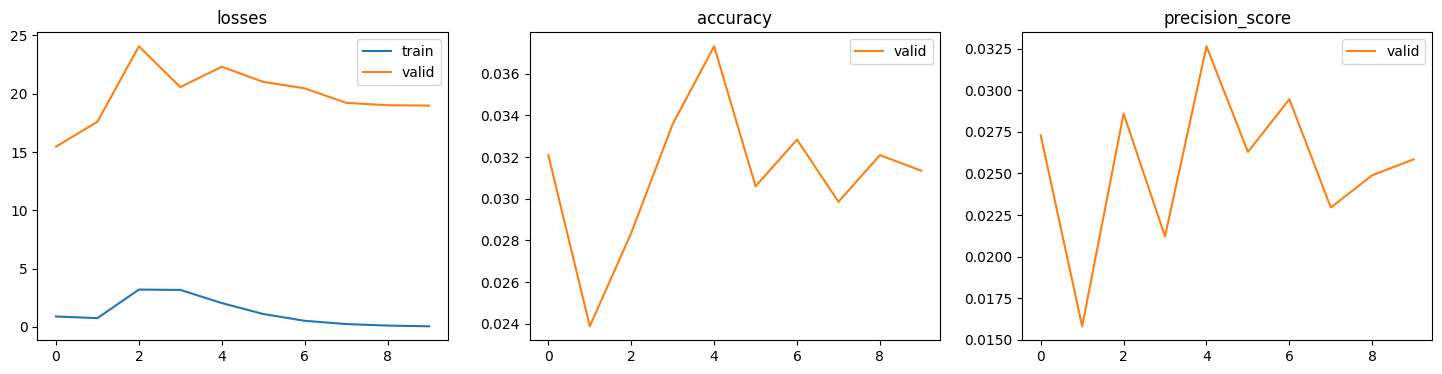

In [ ]:
learn4.fine_tune(epochs=10, freeze_epochs=5)
learn4.recorder.plot_metrics()

Observaciones:
*   Los resultados de las métricas son extremadamente malos. Tanto accuracy como precision dan entorno al 3%. Es prácticamente igual a asignar una clase aleatoria.
*   Además, se puede apreciar sobreajuste ( aunque más que sobreajuste es un mal ajuste ) prácticamente desde el inicio.

Con respecto a la pregunta planteada, tenemos dos experimentos usando la misma arquitectura de red ( salvo por el valor de salida ), donde en ambos se entrenan las mismas épocas totales y freeze_epochs y con pesos preentrenados. Esto se podía intuir desde el experimento de regresión. Como hemos visto, teníamos gracias al **MSE** Y **MAE** que el error medio cometido ( no es exactamente la interpretación de ambas pero nos ayudan a saber cuál suele ser el error cometido en la predicción ) estaba entre 6 y 8 años. Por tanto, si normalmente nos equivocamos unos 6 años en cada predicción es normal que si llevamos este problema a clasificación no tengamos casi ningún acierto ya que en ese caso es lo mismo equivocarse por 1 año que por 20 en cuanto a las métricas y por tanto sean tan malas. El factor clave para decidir que es mejor está en lo anterior. Las etiquetas presentan una relación de distancia y por tanto no es igual de incorrecto en una radiografía de un paciente de edad 57, que la predicción sea 56 a que sea 18, que es lo que sucede en clasificación. En mi opinión, es mejor opción regresión por la explicabilidad de las métricas en cuanto a lo cercano a la edad real en la predicción. De todos modos, se usa el mismo cuerpo que se encarga mayoritariamente de extracción de características. Esto no quiere decir que si regresión predice "x", el modelo de clasificación también vaya a predecir "x" o cercano, pero es esperable que con un modelo preentrenado, al entrenar después en pocas épocas en ambos casos, los resultados puedan ser similares. Aún esperando que fueran similares, no van a ser los mismos pese a que el cuerpo sea el mismo, ya que al entrenar toda la red en ambos modelos, se produce una actualización de parámetros con objetivo de minimizar la función de pérdida y no es lo mismo minimizar **MSE** que **CrossEntropy** luego los pesos son diferentes tras el fine tuning.